In [1]:
####les bibliotheques a telecharger##
import mediapipe as mp             
import cv2
import numpy as np
import matplotlib.pyplot as plt
import win32api #pour la souris
import win32con #
import time
from tkinter import *
###############################

In [2]:
def calculate_angle(left_shoulder,left_elbow): # Calcule l'angle du bras a partir des coordonees (x,y) du bras et de l'epaule
    a=np.array(left_shoulder)
    b=np.array(left_elbow)
    radians=np.arctan2(b[0]-a[0],b[1]-a[1])
    angle=np.abs(radians*180.0/np.pi)
    return angle

In [3]:
#### Cette fonction gere les clicks, elle est appelee a chaque image et renvoit l'etat de Etat_acquisition pour l'image suivante #########
def mousePoints(event,x,y,flags,params):
    win32api.SetCursor(win32api.LoadCursor(0, win32con.IDC_ARROW))
    global Liste_mesures
    global Etat_acquisition
    global angle_max
    global time_depart
    if event == cv2.EVENT_LBUTTONDOWN :
        print(x,y) # Juste pour m'aider a recuperer les coordonnees de certains points a l'ecran
        
    # Pour afficher un curseur main sur les bouttons
    if event == cv2.EVENT_MOUSEMOVE:
        if (x>=6 and x<=495 and y>=6 and y<=40) or (x>=1200 and x<=1277 and y>=675 and y<=710) or (x>=6 and x<=397 and y>=675 and y<=710):
            win32api.SetCursor(win32api.LoadCursor(0, win32con.IDC_HAND))

    if event == cv2.EVENT_MOUSEMOVE:
        if ((x>=64 and x<=198 and y>=79 and y<=110) or (x>=266 and x<=402 and y>=79 and y<=110)) and Etat_acquisition=="Renseignement":
            win32api.SetCursor(win32api.LoadCursor(0, win32con.IDC_HAND))
            
    # Bouton acquisition       
    if event == cv2.EVENT_LBUTTONDOWN :
        if x>=6 and x<=495 and y>=6 and y<=40:
            if Etat_acquisition=="Accueil":
                Etat_acquisition="Timer"
                time_depart=time.time()
           
    if event == cv2.EVENT_LBUTTONDOWN:
        if x>=6 and x<=495 and y>=6 and y<=40:
            if Etat_acquisition=="EnAcquisition":
                Etat_acquisition="Renseignement"

    # Bouton pour enregistrer une valeur: fait appel a un fichier texte            
    if event == cv2.EVENT_LBUTTONDOWN:
        if Etat_acquisition=="Renseignement":
            if x>=64 and x<=198 and y>=79 and y<=110:

                print("L'angle maximal atteint par le joueur est:",int(angle_max))
                nom=input("Entrez le nom du joueur:")
                mois=input("Entrez le mois (en chiffre):")
                fichier = open("donnees.txt", "a")
                fichier.write(nom+","+str(int(angle_max))+","+str(mois)+"\n")
                fichier.close()

                Etat_acquisition="Accueil"
    #Bouton pour le refus d'enregistrer une valeur            
    if event == cv2.EVENT_LBUTTONDOWN:
        if Etat_acquisition=="Renseignement":
            if x>=266 and x<=402 and y>=79 and y<=110:
                Etat_acquisition="Accueil"

    # Boutton pour visualiser les courbes            
    if event == cv2.EVENT_LBUTTONDOWN:
        if x>=6 and x<=397 and y>=675 and y<=710:
            if Etat_acquisition=="Accueil":
                
                fichier = open("donnees.txt", "r")
                lignes=fichier.readlines()
                fichier.close()
                
                Lpatients=[]
                lpat=""
                for mesure in lignes:
                    mesure_liste=mesure.split(",")
                    if mesure_liste[0] not in Lpatients:
                        Lpatients.append(mesure_liste[0])
                        lpat=lpat+mesure_liste[0]+" "
                        
                print("Les joueurs enregistrés sont:"+lpat)
                nom=input("Joueur a analyser:")     
                liste_mesures=[]
                liste_mois=[]
                for mesure in lignes:
                    mesure_liste=mesure.split(",")
                    if mesure_liste[0]==nom:
                        liste_mesures.append(int(mesure_liste[1]))
                        liste_mois.append(mesure_liste[2][0])
                plt.title("Evolution du joueur "+nom)
                plt.xlabel("mois")
                plt.ylabel("Angle du bras gauche en deg")
                plt.plot(liste_mois,liste_mesures)
                plt.show()

    # Bouton quitter            
    if event == cv2.EVENT_LBUTTONDOWN:
        if x>=1200 and x<=1277 and y>=675 and y<=710:
            exit()
            
###############################################################################################################################################
  

# Mettre dans la variable cap le nom de la video a analyser ou 0 pour la webcam

In [4]:
# Etat de demarrage
tic=time.time()
angle_max=0
time_depart=0
Etat_acquisition="Accueil"

# On appel la boucle suivante VIDEO FEED
cap=cv2.VideoCapture('Neymar.mp4') # On active la variable cap qui correspond a la webcam
cap.set(cv2.CAP_PROP_FPS,10)
cap.set(3,2500)
cap.set(4,2500)

# Initialisation des modules Mediapipe
mp_drawing = mp.solutions.drawing_utils # module pour le dessin
mp_pose = mp.solutions.pose # le module d'estimation de pose de mediapipe
#print(mp_pose.POSE_CONNECTIONS)# dictionnaires qui regroupent les keypoints qui doivent etre relies entre eux

In [5]:
# Définition d'une structure de données pour stocker les informations
data_list = []
start_time = 0


# Définissez la taille de la nouvelle image (page à côté de la vidéo)
skeleton_page_width = 800
skeleton_page_height = 600

# Créez une image blanche pour le squelette
skeleton_page = np.ones((skeleton_page_height, skeleton_page_width, 3), np.uint8) * 255

# Définissez la position où vous souhaitez afficher le squelette sur la page
skeleton_position = (50, 50)

# Initialisation de la détection de la pose
with mp_pose.Pose(min_detection_confidence=0.5, min_tracking_confidence=0.5) as pose:

    
    while cap.isOpened():
        ret, frame = cap.read()

        if not ret: # Si la webcam ne renvoit pas d'image on arrete le programme
            print("Erreur lors de la capture d'image.")
            break

        # Recolore l'image car OpenCV travaille avec du BGR et Mediapipe avec du RGB
        img = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Make detection
        results = pose.process(img)  # on stocke dans la variable results le résultat de la fonction pose appliquée à img

        # Vérifiez si la détection a réussi et que results n'est pas None
        if results and results.pose_landmarks:
            # Traitement des résultats ici (pour les afficher on les marque avec des landmarks)
            landmarks = results.pose_landmarks.landmark
            
            # afficher les keypoints
            for landmark in landmarks:
                x, y, z = int(landmark.x * img.shape[1]), int(landmark.y * img.shape[0]), landmark.z
                cv2.circle(img, (x, y), 5, (0, 255, 0), -1)
            
            # Dessin du squelette
            mp_drawing.draw_landmarks(img,results.pose_landmarks,mp_pose.POSE_CONNECTIONS,
                                  mp_drawing.DrawingSpec(color=(0,255,0),thickness=3,circle_radius=2),#paramètre pour les keypoints
                                  mp_drawing.DrawingSpec(color=(255,255,255),thickness=2,circle_radius=2) #paramètre pour les connections
                                  ) #va dessiner sur image les points (results.pose_landmarks) et les liens (mp_pose.POSE_CONNECTIONS) ||

            
            # Get coordinates
            left_shoulder=[landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value].x,landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value].y]
            left_elbow=[landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value].x,landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value].y]
            # Calcule l'angle
            angle=calculate_angle(left_shoulder,left_elbow)
            # Affiche l'angle
            cv2.putText(img,str(int(angle)),
                        tuple(np.multiply(left_shoulder,[1250,700]).astype(int)),
                        cv2.FONT_HERSHEY_SIMPLEX,1,(255,255,255),2,cv2.LINE_AA
                        )
            #Calcul d'angle_max
            if angle>angle_max and Etat_acquisition=="EnAcquisition":
                angle_max=angle

        # Ajoutez les données pendant la période d'acquisition
        if Etat_acquisition == "EnAcquisition":
            # Initialisez le temps au début de l'acquisition
            if start_time == 0:
                start_time = time.time()
                
            # Collectez le temps
            current_time = time.time()

            # Collectez les coordonnées du point du bassin
            hip_coordinates = [
                landmarks[mp_pose.PoseLandmark.LEFT_HIP.value].x,
                landmarks[mp_pose.PoseLandmark.LEFT_HIP.value].y,
                landmarks[mp_pose.PoseLandmark.LEFT_HIP.value].z
            ]

            # Ajoutez ces données à la liste
            data_list.append({
                'time': current_time - start_time,
                'hip_coordinates': hip_coordinates,
                'angle_max': angle_max
            })

        else:
            start_time = 0
        #Tout ce qui suit concerne l'affichage des differents boutons dessines avec opencv
        try:
            if Etat_acquisition=="Accueil":
                cv2.rectangle(img,(6,6),(495,40),(60, 210, 60),-1)
                cv2.rectangle(img,(6,6),(495,40),(0,252,124),0)
                cv2.putText(img,"Cliquez ici pour lancer l'Acquisition",(45,29),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)

                cv2.rectangle(img,(6,675),(397,710),(60, 210, 60),-1)
                cv2.rectangle(img,(6,675),(397,710),(0,252,124),0)
                cv2.putText(img,"Cliquez ici pour afficher courbes",(8,700),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)

                cv2.rectangle(img,(948,675),(1277,710),(60, 210, 60),-1)
                cv2.rectangle(img,(948,675),(1277,710),(0,252,124),0)
                cv2.putText(img,"Appuyer sur 'q' pour Quitter",(951,695),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)

            elif Etat_acquisition=="Timer":
                delay=time.time()-time_depart
                if delay<10.0:
                    cv2.rectangle(img,(6,6),(632,40),(60, 210, 60),-1)
                    cv2.rectangle(img,(6,6),(632,40),(0,252,124),0)
                    cv2.putText(img,"[Timer]  Il reste:"+str(int(10.0-delay))+"s  Installez vous face a la camera",(10,29),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)

                    cv2.rectangle(img,(948,675),(1277,710),(60, 210, 60),-1)
                    cv2.rectangle(img,(948,675),(1277,710),(0,252,124),0)
                    cv2.putText(img,"Appuyer sur 'q' pour Quitter",(951,695),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)
                
                else:
                    angle_max=0
                    Etat_acquisition="EnAcquisition"
                    
            elif Etat_acquisition=="EnAcquisition":
                cv2.rectangle(img,(6,6),(495,40),(60, 210, 60),-1)
                cv2.rectangle(img,(6,6),(495,40),(0,252,124),0)
                cv2.putText(img,"Acquisition en cours, cliquez pour Arreter",(10,29),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)

                cv2.rectangle(img,(6,45),(252,75),(60, 210, 60),-1)
                cv2.rectangle(img,(6,45),(252,75),(0,252,124),0)
                cv2.putText(img,"Angle max (deg):"+str(int(angle_max)),(10,65),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)

                cv2.rectangle(img,(948,675),(1277,710),(60, 210, 60),-1)
                cv2.rectangle(img,(948,675),(1277,710),(0,252,124),0)
                cv2.putText(img,"Appuyer sur 'q' pour Quitter",(951,695),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)
        
            elif Etat_acquisition=="Renseignement":
                cv2.rectangle(img,(6,6),(495,75),(60, 210, 60),-1)
                cv2.rectangle(img,(6,6),(495,75),(0,252,124),0) 
                cv2.putText(img,"Acquisition finie, Enregistrer valeur?",(35,43),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)
                
                cv2.rectangle(img,(64,79),(198,110),(60, 210, 60),-1)
                cv2.rectangle(img,(64,79),(198,110),(0,252,124),0)
                cv2.putText(img,"OUI",(111,102),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)
                
                cv2.rectangle(img,(266,79),(402,110),(60, 210, 60),-1)
                cv2.rectangle(img,(266,79),(402,110),(0,252,124),0)
                cv2.putText(img,"NON",(312,102),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)

                cv2.rectangle(img,(948,675),(1277,710),(60, 210, 60),-1)
                cv2.rectangle(img,(948,675),(1277,710),(0,252,124),0)
                cv2.putText(img,"Appuyer sur 'q' pour Quitter",(951,695),cv2.FONT_HERSHEY_DUPLEX,0.7,(255,255,255),1)
        except:
            pass

        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)  # on repasse l'image en BGR pour OpenCV
        

        # Par exemple, afficher l'image modifiée
        cv2.imshow('Webcam Feed', img)
        cv2.setMouseCallback("Webcam Feed",mousePoints)
        
        # Réinitialiser l'image du squelette à chaque itération
        skeleton_page = np.ones((skeleton_page_height, skeleton_page_width, 3), np.uint8) * 100
        mp_drawing.draw_landmarks(skeleton_page, results.pose_landmarks, mp_pose.POSE_CONNECTIONS,
                          landmark_drawing_spec=mp_drawing.DrawingSpec(color=(0, 255, 0), thickness=3, circle_radius=2),
                          connection_drawing_spec=mp_drawing.DrawingSpec(color=(255, 255, 255), thickness=2, circle_radius=2))



        
         # Affichez la vidéo et le squelette côte à côte
        combined_display = np.hstack((cv2.resize(img, (skeleton_page.shape[1], skeleton_page.shape[0])), skeleton_page))

        cv2.imshow('Combined Display', combined_display)
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()


172 21
436 31


In [6]:
data_list

[{'time': 0.0,
  'hip_coordinates': [0.5898787975311279,
   1.5349715948104858,
   -0.07124479115009308],
  'angle_max': 45.22583187094548},
 {'time': 0.03369927406311035,
  'hip_coordinates': [0.5898273587226868,
   1.5348166227340698,
   -0.0685422495007515],
  'angle_max': 45.457692486482024},
 {'time': 0.0666649341583252,
  'hip_coordinates': [0.5898085832595825,
   1.5347402095794678,
   -0.06680260598659515],
  'angle_max': 45.55543376535962},
 {'time': 0.09679746627807617,
  'hip_coordinates': [0.5897687077522278,
   1.5384280681610107,
   -0.06633041054010391],
  'angle_max': 45.57636838152644},
 {'time': 0.12786650657653809,
  'hip_coordinates': [0.5892482399940491,
   1.538379430770874,
   -0.06460794061422348],
  'angle_max': 45.57636838152644},
 {'time': 0.15949678421020508,
  'hip_coordinates': [0.5888646841049194,
   1.5383983850479126,
   -0.06372396647930145],
  'angle_max': 45.57636838152644},
 {'time': 0.19019246101379395,
  'hip_coordinates': [0.588828444480896,
   1

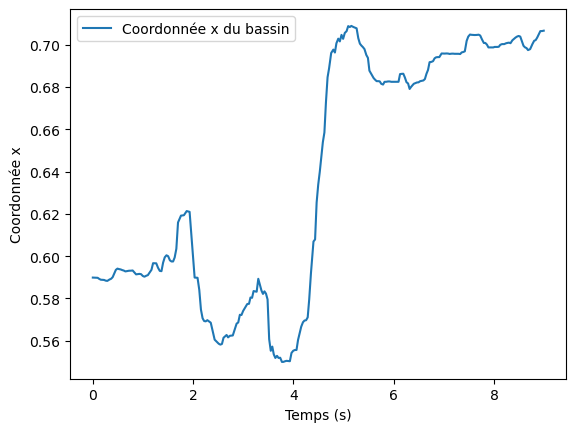

In [7]:
time_list = [entry['time'] for entry in data_list]
x_hip_list = [entry['hip_coordinates'][0] for entry in data_list]
y_hip_list = [entry['hip_coordinates'][1] for entry in data_list]

# Tracez la courbe en temps réel
plt.plot(time_list, x_hip_list, label='Coordonnée x du bassin')
plt.xlabel('Temps (s)')
plt.ylabel('Coordonnée x')
plt.legend()
plt.show()

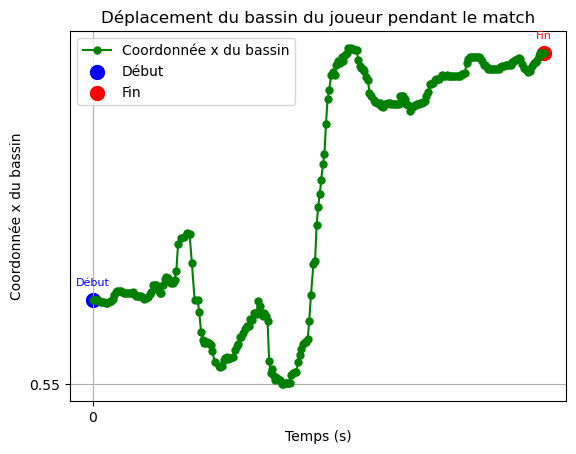

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Supposons que vous avez déjà défini time_list, x_hip_list

# Tracer la courbe avec une ligne solide et des marqueurs
plt.plot(time_list, x_hip_list, marker='o', markersize=5, linestyle='-', color='green', label='Coordonnée x du bassin')

# Ajouter des marqueurs au début et à la fin avec une taille plus grande
plt.scatter(time_list[0], x_hip_list[0], color='blue', label='Début', s=100)
plt.scatter(time_list[-1], x_hip_list[-1], color='red', label='Fin', s=100)

# Ajouter des annotations au-dessus des points de début et de fin
plt.annotate('Début', (time_list[0], x_hip_list[0]), textcoords="offset points", xytext=(0,10), ha='center', fontsize=8, color='blue')
plt.annotate('Fin', (time_list[-1], x_hip_list[-1]), textcoords="offset points", xytext=(0,10), ha='center', fontsize=8, color='red')

# Ajouter un titre et des étiquettes d'axe
plt.title("Déplacement du bassin du joueur pendant le match")
plt.xlabel('Temps (s)')
plt.ylabel('Coordonnée x du bassin')

# Personnaliser les graduations des axes
plt.xticks(np.arange(min(time_list), max(time_list)+1, 10.0))
plt.yticks(np.arange(min(x_hip_list), max(x_hip_list)+1, 5.0))

# Ajouter une grille pour une meilleure lisibilité
plt.grid(True)

# Ajouter une légende
plt.legend()

# Afficher le graphique
plt.show()


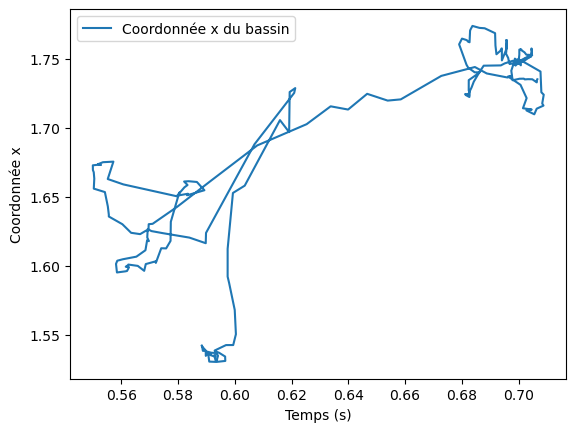

In [9]:
time_list = [entry['time'] for entry in data_list]
x_hip_list = [entry['hip_coordinates'][0] for entry in data_list]
y_hip_list = [entry['hip_coordinates'][1] for entry in data_list]

# Tracez la courbe en temps réel
plt.plot(x_hip_list, y_hip_list, label='Coordonnée x du bassin')
plt.xlabel('Temps (s)')
plt.ylabel('Coordonnée x')
plt.legend()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Supposons que vous avez déjà défini time_list, x_hip_list, et y_hip_list

# Générer des couleurs graduelles en fonction du temps
colors = np.arange(len(time_list))

# Tracer la courbe avec des gradations de couleurs
plt.scatter(x_hip_list, y_hip_list, c=colors, cmap='viridis', label='Coordonnée x du bassin')

plt.xlabel('Coordonnée x du bassin')
plt.ylabel('Coordonnée y du bassin')
plt.colorbar(label='Temps (s)')

plt.legend()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Supposons que vous avez déjà défini time_list, x_hip_list, et y_hip_list

# Générer des couleurs graduelles en fonction du temps
colors = np.arange(len(time_list))

# Tracer la courbe avec des gradations de couleurs
plt.scatter(x_hip_list, y_hip_list, c=colors, cmap='viridis', label='Coordonnée x du bassin')

plt.xlabel('Coordonnée x du bassin')
plt.ylabel('Coordonnée y du bassin')
plt.colorbar(label='Temps (s)')

# Ajuster l'échelle des axes selon les valeurs min/max de vos données
plt.axis([min(x_hip_list), max(x_hip_list), min(y_hip_list), max(y_hip_list)])

plt.legend()
plt.show()
